# orbitguard walkthrough

One end-to-end pass through the library, using live public data:

1. Load the public catalog and screen **NISAR** for close approaches.
2. Score them with assumed vs **Spacebook** synthetic covariance.
3. Turn relative speed into shield damage with the **ballistic limit equation**, and check it with **SPH**.
4. Build the **orbital-shell grid** and compare debris exposure across assets.
5. Cross-check our asteroid **MOID** against JPL.

Numbers change daily because the inputs are live.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from orbitguard.ingest.celestrak import fetch_catalog
catalog = fetch_catalog()
by_id = {t.norad_id: t for t in catalog}
kinds = np.array([2 if t.is_debris else 0 for t in catalog])
print(f"{len(catalog):,} objects, {int((kinds == 2).sum()):,} debris/rocket bodies")

32,769 objects, 12,407 debris/rocket bodies


## 1. Conjunction screening for NISAR (next 3 days)

In [2]:
import time
from orbitguard.orbit import rescore, screen
from orbitguard.orbit.covariance import spacebook_provider

nisar = by_id[65053]
t = time.time()
assumed = screen(nisar, catalog, days=3)
print(f"screened {len(catalog):,} objects in {time.time() - t:.1f} s -> {len(assumed)} approaches < 10 km")
# Same geometry, Pc recomputed with Spacebook's per-object synthetic covariance
realistic = rescore(assumed, spacebook_provider)

screened 32,769 objects in 16.1 s -> 45 approaches < 10 km


In [3]:
rows = []
for c, r in list(zip(assumed, realistic))[:10]:
    rows.append((c.tca.strftime("%m-%d %H:%M"), c.secondary.name[:22], c.miss_km, c.rel_speed_kms, c.pc,
                 r.pc, r.cov_source))
print(f"{'TCA':12} {'object':22} {'miss km':>8} {'km/s':>6} {'Pc assumed':>11} {'Pc Spacebook':>13}  source")
for row in rows:
    print(f"{row[0]:12} {row[1]:22} {row[2]:8.2f} {row[3]:6.2f} {row[4]:11.1e} {row[5]:13.1e}  {row[6]}")

TCA          object                  miss km   km/s  Pc assumed  Pc Spacebook  source
10-23 04:36  IRIDIUM 33 DEB             2.97  14.48     3.3e-06       0.0e+00  spacebook
10-24 11:26  METEOR 2-5 DEB             3.71  14.32     1.1e-06       6.9e-07  spacebook
10-24 13:06  METEOR 2-5 DEB             5.67  14.33     8.8e-07       6.6e-07  spacebook
10-23 22:13  COSMOS 2251 DEB            7.98   8.63     1.4e-08       1.9e-09  spacebook
10-23 15:32  COSMOS 2251 DEB            8.56  10.72     1.3e-08       2.1e-37  spacebook
10-23 02:13  FENGYUN 1C DEB             3.57  12.67     1.5e-09       8.7e-82  spacebook
10-22 09:16  COSMOS 2251 DEB            9.27   3.99     1.1e-09       1.1e-09  spacebook+assumed
10-22 19:30  NOAA 16 DEB                7.94   5.59     7.2e-10       5.0e-32  spacebook
10-24 10:36  METEOR 2-5 DEB             7.09  14.28     1.9e-10       4.0e-08  spacebook
10-24 08:56  METEOR 2-5 DEB             7.38  14.28     1.7e-10       5.6e-09  spacebook


## 2. What happens if one of these hits?

The Christiansen Whipple-shield BLE gives the smallest aluminium particle that perforates the rear
wall. Below 3 km/s the projectile stays intact (ballistic); above 7 km/s it shatters on the bumper
and the debris cloud spreads. That's why the curve *rises* between 3 and 7 km/s.

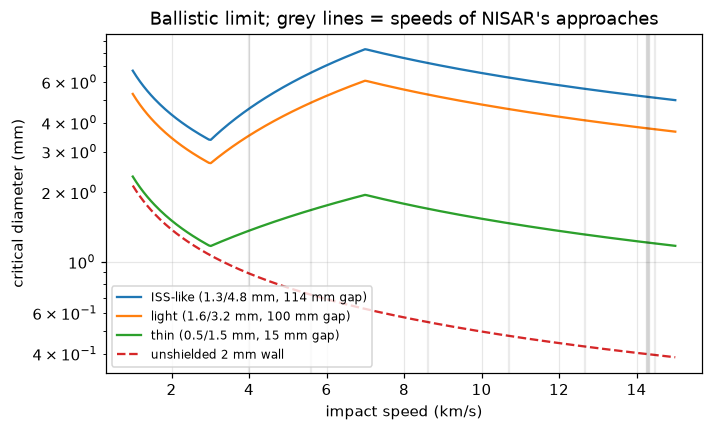

In [4]:
from orbitguard.impact import WhippleShield, SingleWall
v = np.linspace(1, 15, 300)
fig, ax = plt.subplots(figsize=(7, 4))
for label, s in [("ISS-like (1.3/4.8 mm, 114 mm gap)", WhippleShield(0.127, 0.48, 11.4)),
                 ("light (1.6/3.2 mm, 100 mm gap)", WhippleShield()),
                 ("thin (0.5/1.5 mm, 15 mm gap)", WhippleShield(0.05, 0.15, 1.5))]:
    ax.plot(v, s.critical_diameter(v) * 10, label=label)
ax.plot(v, SingleWall(0.2).critical_diameter(v) * 10, "--", label="unshielded 2 mm wall")
for c in assumed[:10]:
    ax.axvline(c.rel_speed_kms, color="k", alpha=0.08)
ax.set(xlabel="impact speed (km/s)", ylabel="critical diameter (mm)", yscale="log",
       title="Ballistic limit; grey lines = speeds of NISAR's approaches")
ax.legend(fontsize=8); plt.show()

SPH: 4,738 particles, 12 s
{'time_us': 3.25, 'bumper_hole_mm': 4.5, 'hole_to_projectile': 2.25, 'cloud_half_angle_deg': 43.27, 'rear_wall_max_displacement_mm': 2.02, 'rear_wall_perforated': True, 'p99_pressure_GPa': 39.47}
BLE says this shield stops particles up to 1.95 mm


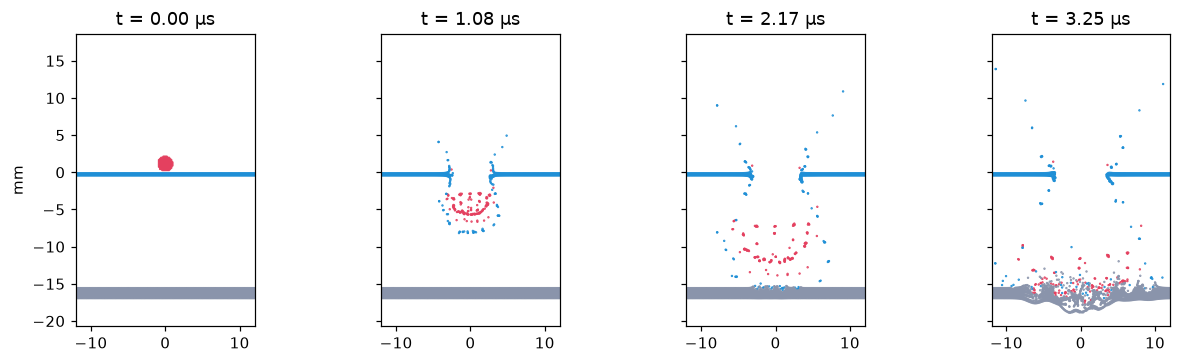

In [5]:
from orbitguard.impact import WhippleImpact, damage_metrics
sc = WhippleImpact(projectile_diameter=2.0, speed=7.0, resolution=0.15)
sol = sc.build(); pos0 = sol.state.pos0.copy()
t = time.time(); frames = sol.run(sc.time_to_rear_wall() * 1.3, snapshots=4)
print(f"SPH: {len(pos0):,} particles, {time.time() - t:.0f} s")
print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in damage_metrics(sc, frames[-1], pos0).items()})
print(f"BLE says this shield stops particles up to {float(WhippleShield(0.05, 0.15, 1.5).critical_diameter(7.0)) * 10:.2f} mm")

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), sharey=True)
colors = np.array(["#e4405f", "#1f8fd6", "#8a94ab"])
for ax, f in zip(axes, frames):
    ax.scatter(f["pos"][:, 0], f["pos"][:, 1], s=0.3, c=colors[f["body"]])
    ax.set(title=f"t = {f['t']:.2f} µs", xlim=(-12, 12), aspect="equal"); ax.grid(False)
axes[0].set_ylabel("mm"); plt.tight_layout(); plt.show()

## 3. Orbital-shell grid and debris exposure

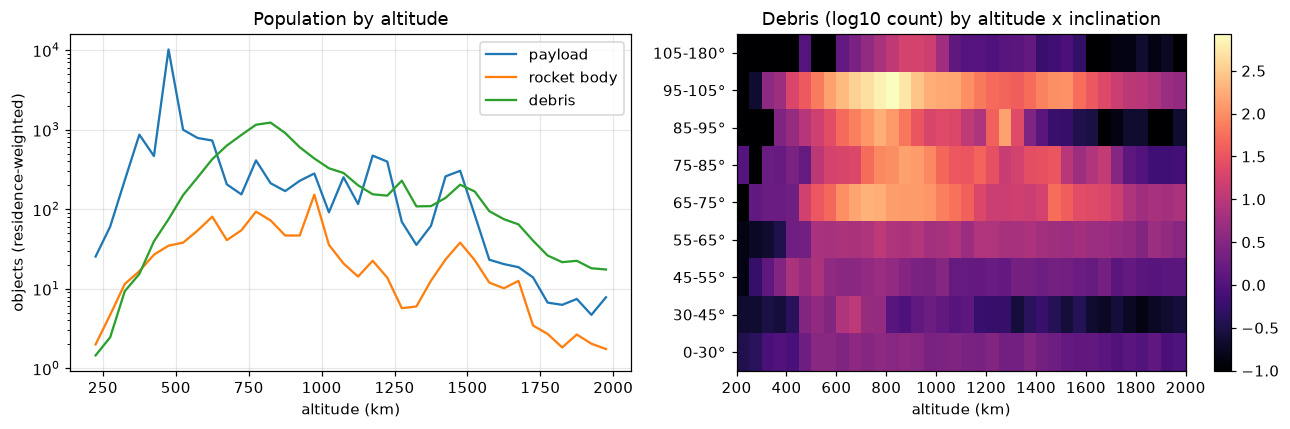

In [6]:
from orbitguard.risk import ALT_EDGES, INC_EDGES, build_grid, asset_risk
grid = build_grid(catalog)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
alt = 0.5 * (ALT_EDGES[:-1] + ALT_EDGES[1:])
for k, name in enumerate(["payload", "rocket body", "debris"]):
    ax[0].plot(alt, grid.counts[..., k].sum(1), label=name)
ax[0].set(xlabel="altitude (km)", ylabel="objects (residence-weighted)", yscale="log", title="Population by altitude")
ax[0].legend()
im = ax[1].imshow(np.log10(grid.counts[..., 2].T + 0.1), origin="lower", aspect="auto",
                  extent=[ALT_EDGES[0], ALT_EDGES[-1], 0, len(INC_EDGES) - 1], cmap="magma")
ax[1].set_yticks(np.arange(len(INC_EDGES) - 1) + 0.5,
                 [f"{a:.0f}-{b:.0f}°" for a, b in zip(INC_EDGES[:-1], INC_EDGES[1:])])
ax[1].set(xlabel="altitude (km)", title="Debris (log10 count) by altitude x inclination"); ax[1].grid(False)
fig.colorbar(im, ax=ax[1]); plt.tight_layout(); plt.show()

In [7]:
assets = [25544, 48274, 20580, 39634, 65053]  # ISS, Tiangong, Hubble, Sentinel-1A, NISAR
reps = [asset_risk(by_id[a], grid, days=365, area_m2=100) for a in assets]
for r in reps:
    print(f"{r.asset:14} catalog-debris flux {r.flux_catalog_per_m2_yr:.2e} /m2/yr   "
          f"P(penetration, 100 m2, 1 yr) = {r.p_penetration:.2%}")
print("\nSmall-debris slopes are uncalibrated defaults; compare ratios between assets, not absolutes.")

ISS (ZARYA)    catalog-debris flux 7.20e-07 /m2/yr   P(penetration, 100 m2, 1 yr) = 0.41%
CSS (TIANHE-1) catalog-debris flux 3.53e-07 /m2/yr   P(penetration, 100 m2, 1 yr) = 0.20%
HST            catalog-debris flux 1.17e-06 /m2/yr   P(penetration, 100 m2, 1 yr) = 0.67%
SENTINEL 1A    catalog-debris flux 6.79e-06 /m2/yr   P(penetration, 100 m2, 1 yr) = 3.83%
NISAR          catalog-debris flux 1.10e-05 /m2/yr   P(penetration, 100 m2, 1 yr) = 6.13%

Small-debris slopes are uncalibrated defaults; compare ratios between assets, not absolutes.


## 4. Asteroids: our MOID vs JPL's

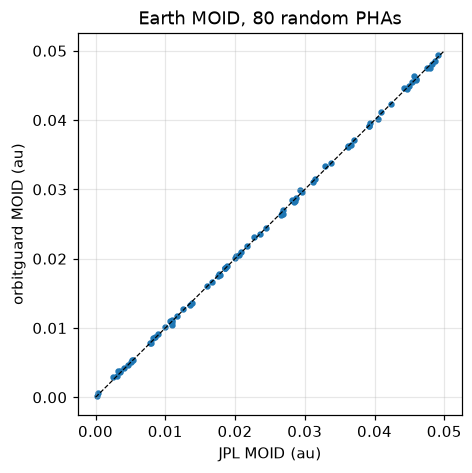

median |diff| 9.8e-05 au (0.038 lunar distances), max 6.8e-04 au


In [8]:
from orbitguard.live import neo
pha = neo.fetch_population("pha")
rng = np.random.default_rng(1)
sample = [pha[i] for i in rng.choice(len(pha), 80, replace=False)]
ours = np.array([neo.moid(o) for o in sample]); jpl = np.array([o.jpl_moid for o in sample])
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(jpl, ours, s=10); ax.plot([0, 0.05], [0, 0.05], "k--", lw=0.8)
ax.set(xlabel="JPL MOID (au)", ylabel="orbitguard MOID (au)", title="Earth MOID, 80 random PHAs")
plt.show()
d = np.abs(ours - jpl)
print(f"median |diff| {np.median(d):.1e} au ({np.median(d) / neo.LD_AU:.3f} lunar distances), max {d.max():.1e} au")

## Next

Phase 3 (forecasting) needs historical catalog snapshots from Space-Track.org:

```bash
export SPACETRACK_USER=...  SPACETRACK_PASS=...
orbitguard history --start 2021-01-04 --end 2026-10-01 --step 7
orbitguard train --horizon 4
```